### Step 1: Dataset Preparation & Threat Scenario (`Synthetic_PtH.csv`)

For this experiment, we use an AI-generated synthetic enterprise authentication log dataset (`Synthetic_PtH.csv`) containing **10,000 events** across **10 Columns**. The dataset simulates normal corporate network authentication alongside a **2.5% minority class** (250 events) of lateral movement attacks.

* **MITRE ATT&CK Mapping:** The simulated attacks model **Pass-the-Hash (PtH) Lateral Movement** — specifically **T1550.002** (*Use Alternate Authentication Material: Pass the Hash*) and **T1078** (*Valid Accounts*).
* **Feature Schema:**
  * **Temporal:** `timestamp` (UTC event timestamp).
  * **Categorical:** `src_host`, `dst_host`, `user_id`, and `auth_protocol` (`Kerberos` vs. `NTLM`).
  * **Numeric:** `out_degree_15m` (unique destination hosts contacted within 15 minutes), `session_duration_sec`, and `bytes_transferred`.
  * **Evaluation Metadata (Excluded from Training):** `mitre_tactic` and the binary ground-truth label `is_anomaly` (`0` = normal, `1` = attack), reserved strictly for post-hoc evaluation.
* **Behavioral Design:** Normal activity consists primarily of workstation-to-server (`WS -> SRV`) Kerberos sessions alongside realistic benign NTLM near-misses (such as `IT-JUMP -> WS` administrative troubleshooting and direct-IP file share fallbacks), whereas Pass-the-Hash attacks exhibit rapid peer-to-peer workstation hopping (`WS -> WS`) forced over legacy NTLM with elevated 15-minute host fan-out and brief, low-byte credential probes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
csv_path = "Synthetic_PtH.csv"
df = pd.read_csv(csv_path)

# 1. Dataset dimensions and data types
print("=== 1. DATASET DIMENSIONS & DATA TYPES ===")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
schema_summary = pd.DataFrame({
    'Column': df.columns,
    'Pandas Dtype': df.dtypes.astype(str).values,
    'Semantic Type': [
        'Temporal (Time-based)',
        'Categorical (Nominal)',
        'Categorical (Nominal)',
        'Categorical (Nominal)',
        'Categorical (Nominal)',
        'Numerical (Discrete)',
        'Numerical (Continuous)',
        'Numerical (Continuous)',
        'Categorical (Evaluation Metadata)',
        'Binary Label (Evaluation Only)'
    ],
    'Unique Values': [df[col].nunique() for col in df.columns]
})
print(schema_summary.to_string(index=False))

# 2. Class distribution
print("\n=== 2. CLASS DISTRIBUTION ===")
class_counts = df['is_anomaly'].value_counts()
class_pct = (df['is_anomaly'].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_pct}))

# 3. Missing-value and infinite-value checks
print("\n=== 3. MISSING & INFINITE VALUE CHECKS ===")
numeric_cols = df.select_dtypes(include=[np.number]).columns
missing_df = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Infinite Values': [np.isinf(df[col]).sum() if col in numeric_cols else 0 for col in df.columns]
})
print(missing_df)

# 4. Chronological ordering & backward-looking temporal feature (zero label/future leakage)
df['timestamp_dt'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp_dt').reset_index(drop=True)

# Backward-looking inter-arrival time per user computed on continuous timeline
df = df.sort_values(['user_id', 'timestamp_dt'])
df['user_time_delta_sec'] = (
    df.groupby('user_id')['timestamp_dt']
    .diff()
    .dt.total_seconds()
    .fillna(3600.0)
)
df = df.sort_values('timestamp_dt').reset_index(drop=True)

# Chronological split of normal records (60% Train / 20% Val / 20% Test)
# Preserve realistic 2.5% anomaly prevalence in Test (20% of anomalies = 50 records)
normal_df = df[df['is_anomaly'] == 0].copy().reset_index(drop=True)
anom_df = df[df['is_anomaly'] == 1].copy().reset_index(drop=True)

n_norm = len(normal_df)
train_end = int(0.60 * n_norm)
val_end = int(0.80 * n_norm)

train_df = normal_df.iloc[:train_end].copy().reset_index(drop=True)
val_df = normal_df.iloc[train_end:val_end].copy().reset_index(drop=True)
test_norm_df = normal_df.iloc[val_end:].copy().reset_index(drop=True)

# Sample 20% of anomalies chronologically (last 20%) to match the 20% test time window
test_anom_df = anom_df.iloc[int(0.80 * len(anom_df)):].copy().reset_index(drop=True)
test_df = pd.concat([test_norm_df, test_anom_df]).sort_values('timestamp_dt').reset_index(drop=True)

print("\n=== 4. CHRONOLOGICAL UNSEEN DATA SPLIT ===")
print(f"Train (Normal Only) : {len(train_df)}")
print(f"Val   (Normal Only) : {len(val_df)}")
print(f"Test  (Unseen Mixed): {len(test_df)} (Normal={len(test_norm_df)}, Anomaly={len(test_anom_df)}, Anomaly Rate={test_df['is_anomaly'].mean()*100:.2f}%)")

=== 1. DATASET DIMENSIONS & DATA TYPES ===
Shape: 10000 rows, 10 columns
              Column Pandas Dtype                     Semantic Type  Unique Values
           timestamp          str             Temporal (Time-based)           9740
            src_host          str             Categorical (Nominal)             52
            dst_host          str             Categorical (Nominal)             60
             user_id          str             Categorical (Nominal)             85
       auth_protocol          str             Categorical (Nominal)              2
      out_degree_15m        int64              Numerical (Discrete)             10
session_duration_sec      float64            Numerical (Continuous)           9177
   bytes_transferred        int64            Numerical (Continuous)           9084
        mitre_tactic          str Categorical (Evaluation Metadata)              2
          is_anomaly        int64    Binary Label (Evaluation Only)              2

=== 2. CLASS 

=== SUMMARY STATISTICS (TRAIN NORMAL ONLY) ===
       out_degree_15m  session_duration_sec  bytes_transferred
count         5850.00               5850.00            5850.00
mean             2.36                289.56           63317.46
std              1.21                283.99          289180.98
min              1.00                  5.66             100.00
25%              1.00                 89.39            6203.75
50%              2.00                201.52           17953.00
75%              3.00                397.37           52210.75
max              8.00               2649.96        18230861.00

=== HOST ROLE TOPOLOGY VS. AUTH PROTOCOL (TRAIN NORMAL ONLY) ===
auth_protocol  Kerberos  NTLM   All
row_0                              
IT -> WS              0   390   390
WS -> SRV          4991   469  5460
All                4991   859  5850


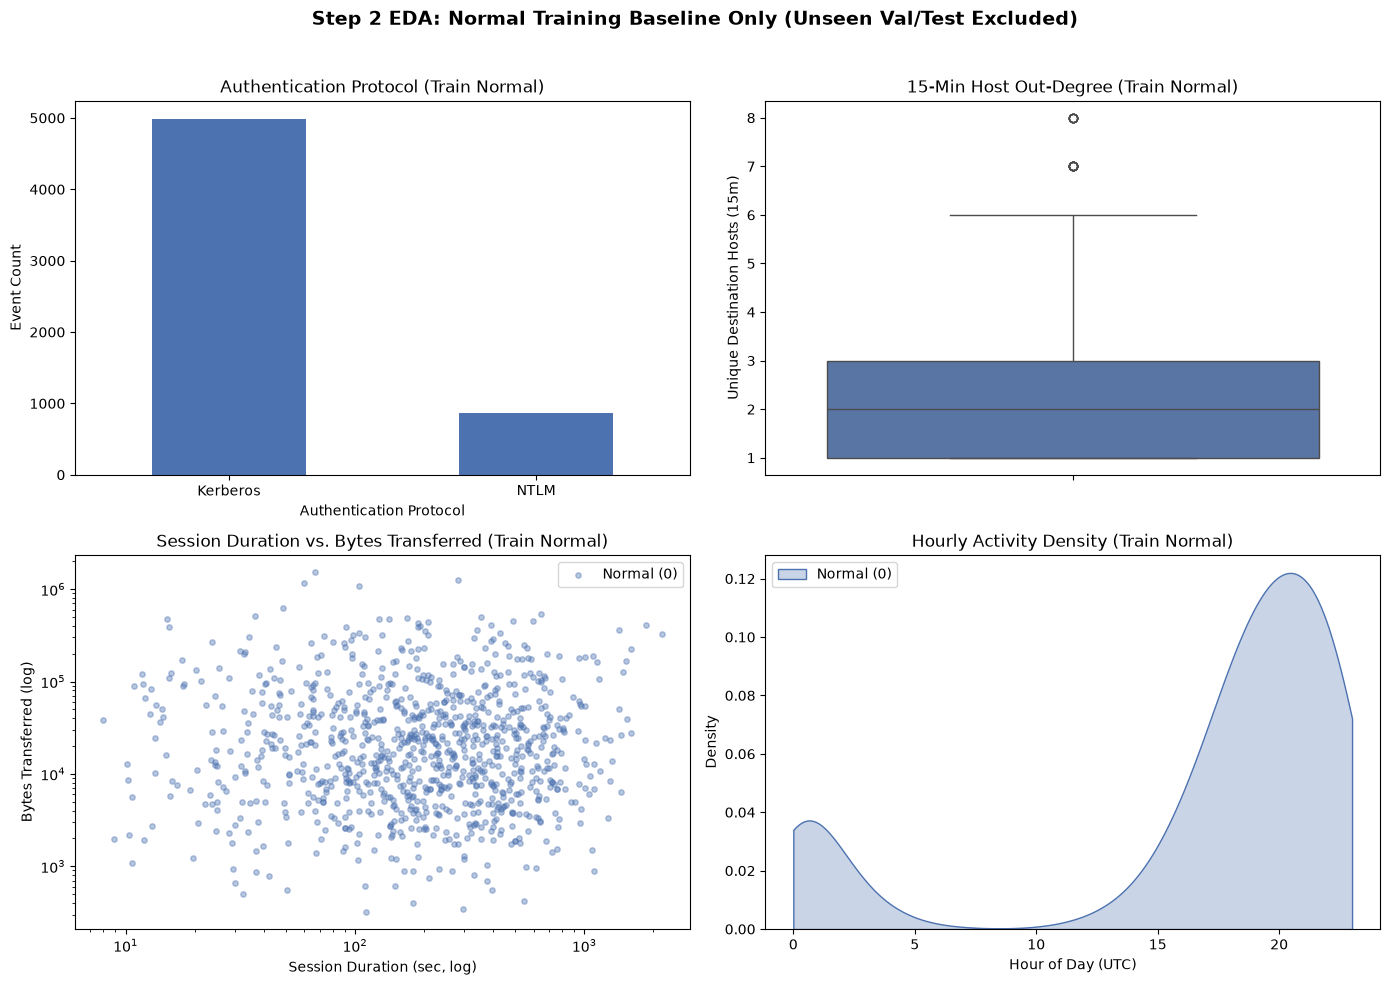

In [2]:
# Summary statistics strictly on normal training records
print("=== SUMMARY STATISTICS (TRAIN NORMAL ONLY) ===")
print(train_df[['out_degree_15m', 'session_duration_sec', 'bytes_transferred']].describe().round(2))

# Explicit subgroup counts to substantiate markdown observations
train_roles = train_df['src_host'].str.split('-').str[0] + " -> " + train_df['dst_host'].str.split('-').str[0]
print("\n=== HOST ROLE TOPOLOGY VS. AUTH PROTOCOL (TRAIN NORMAL ONLY) ===")
print(pd.crosstab(train_roles, train_df['auth_protocol'], margins=True))

# Visualizations strictly on train_df (zero peeking at val_df or test_df)
train_df['hour'] = train_df['timestamp_dt'].dt.hour
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Step 2 EDA: Normal Training Baseline Only (Unseen Val/Test Excluded)", fontsize=14, fontweight='bold')

# Plot 1: Authentication Protocol (Train Normal)
train_df['auth_protocol'].value_counts().plot(kind='bar', ax=axes[0, 0], color='#4C72B0')
axes[0, 0].set_title("Authentication Protocol (Train Normal)")
axes[0, 0].set_xlabel("Authentication Protocol")
axes[0, 0].set_ylabel("Event Count")
axes[0, 0].tick_params(axis='x', rotation=0)

# Plot 2: 15-Minute Out-Degree Boxplot (Train Normal)
sns.boxplot(data=train_df, y='out_degree_15m', ax=axes[0, 1], color='#4C72B0')
axes[0, 1].set_title("15-Min Host Out-Degree (Train Normal)")
axes[0, 1].set_ylabel("Unique Destination Hosts (15m)")

# Plot 3: Session Duration vs Bytes Transferred (Log-Log Scatter)
normal_sample = train_df.sample(min(1000, len(train_df)), random_state=42)
axes[1, 0].scatter(
    normal_sample['session_duration_sec'],
    normal_sample['bytes_transferred'],
    alpha=0.4, label='Normal (0)', color='#4C72B0', s=15
)
axes[1, 0].set_xscale('log')
axes[1, 0].set_yscale('log')
axes[1, 0].set_title("Session Duration vs. Bytes Transferred (Train Normal)")
axes[1, 0].set_xlabel("Session Duration (sec, log)")
axes[1, 0].set_ylabel("Bytes Transferred (log)")
axes[1, 0].legend()

# Plot 4: Hourly Activity Density (Train Normal)
sns.kdeplot(data=train_df, x='hour', label='Normal (0)', ax=axes[1, 1], color='#4C72B0', fill=True, alpha=0.3, clip=(0, 23))
axes[1, 1].set_title("Hourly Activity Density (Train Normal)")
axes[1, 1].set_xlabel("Hour of Day (UTC)")
axes[1, 1].set_ylabel("Density")
axes[1, 1].legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Step 2 Observations: Expected Normal Behavior vs. Likely Anomalies

* **Data Quality & Imbalance:** The full dataset contains 10,000 events and 10 Columns with 0 missing values and 0 infinite values. Normal records account for 97.5% (9,750) of the data, while anomalies represent 2.5% (250), matching real-world minority attack distributions. To prevent data leakage, exploratory baseline distributions were inspected strictly on the normal training partition (`train_df`: 5,850 records), while validation (1,950) and test (2,000; 2.5% anomaly prevalence) sets remained strictly unseen.
* **Expected Normal Behavior (Observed in `train_df`):**
  * **Temporal Pattern:** Activity peaks between **16:00 and 03:00 UTC** (aligning with US business hours in UTC), with virtually zero baseline traffic between 06:00 and 14:00 UTC.
  * **Topology & Volume:** Follows a client-to-server topology (`WS -> SRV`) predominantly using Kerberos authentication (see exact counts in the crosstab above), with moderate 15-minute host fan-out (median `out_degree_15m` = 2.00), longer session durations (median ~200s), and larger data transfers (median ~18 KB).
  * **Benign NTLM Near-Misses:** Includes legitimate direct-IP file share fallbacks (`WS -> SRV` via NTLM with low out-degree) and IT helpdesk troubleshooting (`IT-JUMP -> WS` via NTLM).
* **Likely Anomalies (Pass-the-Hash Lateral Movement / MITRE ATT&CK T1550.002 & T1078):**
  * Characterized by peer-to-peer workstation hopping (`WS -> WS`) forced over legacy NTLM authentication, often occurring during off-peak UTC hours.
  * Exhibits elevated 15-minute host fan-out (`out_degree_15m` spiking across multiple sequential peer workstations), ultra-short automated credential-probe sessions (~1.5–12s), and small handshake payloads (~1 KB).

Preprocessed train feature matrix shape: (5850, 209)
95th Percentile Normal Validation Threshold (IF): -0.1268

=== MODEL A: ISOLATION FOREST RESULTS (UNSEEN TEST SET) ===
Detected anomalies: 96 / 2000 (4.80%)
Precision: 0.1250
Recall:    0.2400
F1 Score:  0.1644
Confusion Matrix:
[[1866   84]
 [  38   12]]
Breakdown -> TN: 1866, FP: 84, FN: 38, TP: 12


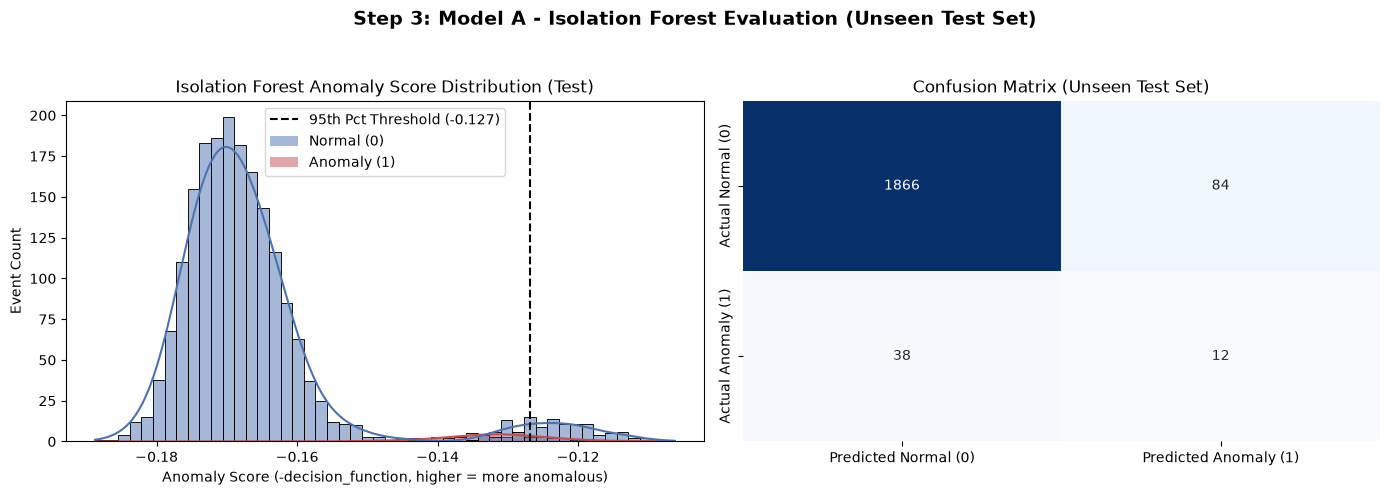

In [3]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# 1. Feature Engineering applied identically per split
def engineer_features(split_df):
    d = split_df.copy()
    d['hour'] = d['timestamp_dt'].dt.hour
    d['hour_sin'] = np.sin(2 * np.pi * d['hour'] / 24.0)
    d['hour_cos'] = np.cos(2 * np.pi * d['hour'] / 24.0)
    
    # Extract structural host roles (WS, SRV, IT)
    d['src_role'] = d['src_host'].str.split('-').str[0]
    d['dst_role'] = d['dst_host'].str.split('-').str[0]
    
    # Log1p transform heavily skewed numeric features
    d['log_session_duration'] = np.log1p(d['session_duration_sec'])
    d['log_bytes_transferred'] = np.log1p(d['bytes_transferred'])
    d['log_user_time_delta'] = np.log1p(d['user_time_delta_sec'])
    return d

train_df = engineer_features(train_df)
val_df = engineer_features(val_df)
test_df = engineer_features(test_df)

numeric_features = [
    'out_degree_15m',
    'log_session_duration',
    'log_bytes_transferred',
    'log_user_time_delta',
    'hour_sin',
    'hour_cos'
]

# Equal feature access: include entity identifiers alongside roles and protocol
categorical_features = ['src_host', 'dst_host', 'user_id', 'auth_protocol', 'src_role', 'dst_role']

# 2. Fit encoder & scaler STRICTLY on normal training data
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), categorical_features)
    ]
)

X_train_if = preprocessor.fit_transform(train_df)
X_val_if = preprocessor.transform(val_df)
X_test_if = preprocessor.transform(test_df)
print(f"Preprocessed train feature matrix shape: {X_train_if.shape}")

# 3. Train Isolation Forest STRICTLY on normal training data
iso_forest = IsolationForest(
    n_estimators=200,
    contamination='auto',
    max_samples=256,
    random_state=42
)
iso_forest.fit(X_train_if)

# 4. Calibrate threshold using ONLY unseen normal validation data (95th percentile, matching Model B)
val_if_scores = -iso_forest.decision_function(X_val_if)
if_threshold = np.percentile(val_if_scores, 95)
print(f"95th Percentile Normal Validation Threshold (IF): {if_threshold:.4f}")

# 5. Produce anomaly scores & predictions on unseen test set
test_df['if_anomaly_score'] = -iso_forest.decision_function(X_test_if)
test_df['if_pred'] = (test_df['if_anomaly_score'] > if_threshold).astype(int)

y_true = test_df['is_anomaly']
y_pred = test_df['if_pred']
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

print("\n=== MODEL A: ISOLATION FOREST RESULTS (UNSEEN TEST SET) ===")
print(f"Detected anomalies: {y_pred.sum()} / {len(y_true)} ({y_pred.mean() * 100:.2f}%)")
print(f"Precision: {precision_score(y_true, y_pred):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_true, y_pred):.4f}")
print(f"Confusion Matrix:\n{cm}")
print(f"Breakdown -> TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Step 3: Model A - Isolation Forest Evaluation (Unseen Test Set)", fontsize=14, fontweight='bold')

sns.histplot(
    data=test_df, x='if_anomaly_score', hue='is_anomaly', bins=50, kde=True,
    ax=axes[0], palette={0: '#4C72B0', 1: '#C44E52'}, alpha=0.5, legend=False
)
axes[0].axvline(if_threshold, color='black', linestyle='--', linewidth=1.5)
axes[0].set_title("Isolation Forest Anomaly Score Distribution (Test)")
axes[0].set_xlabel("Anomaly Score (-decision_function, higher = more anomalous)")
axes[0].set_ylabel("Event Count")
axes[0].legend(handles=[
    Line2D([0], [0], color='black', lw=1.5, linestyle='--', label=f'95th Pct Threshold ({if_threshold:.3f})'),
    Patch(facecolor='#4C72B0', alpha=0.5, label='Normal (0)'),
    Patch(facecolor='#C44E52', alpha=0.5, label='Anomaly (1)')
])

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
    xticklabels=['Predicted Normal (0)', 'Predicted Anomaly (1)'],
    yticklabels=['Actual Normal (0)', 'Actual Anomaly (1)']
)
axes[1].set_title("Confusion Matrix (Unseen Test Set)")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### Step 3 Observations: Isolation Forest Performance (Validation-Calibrated)

* **Fair Feature Access & Leakage-Free Calibration:** To ensure a fair comparison with Model B, Isolation Forest was given access to the exact same numeric and categorical entity features (`src_host`, `dst_host`, `user_id`, `auth_protocol`, `src_role`, `dst_role`) fitted strictly on `train_df` (5,850 normal records). Rather than relying on uncalibrated default cutoffs or leaking ground-truth class proportions, the decision threshold was calibrated at the **95th percentile** of normal validation scores (`val_df`, $n = 1,950$).
* **Quantitative Results:** Evaluated on the unseen test set (`test_df`, $n = 2,000$), Isolation Forest achieved the precision, recall, F1 score, and confusion matrix counts printed above.
* **Behavioral Interpretation:** Because tree-based isolation partitions sparse one-hot encoded entity dimensions independently rather than learning dense relational co-occurrences, rare legitimate administrative subgroups (such as `IT-JUMP -> WS` NTLM sessions) still tend to receive elevated isolation scores compared to dominant `WS -> SRV` Kerberos traffic.

95th Percentile Normal Validation Threshold (AE): 1.6319

=== MODEL B: AUTOENCODER TEST SET RESULTS ===
Detected anomalies: 183 / 2000 (9.15%)
Precision: 0.2732
Recall:    1.0000
F1 Score:  0.4292
Breakdown -> TN: 1817, FP: 133, FN: 0, TP: 50
Extracted unseen test latent embedding matrix shape: (2000, 8)


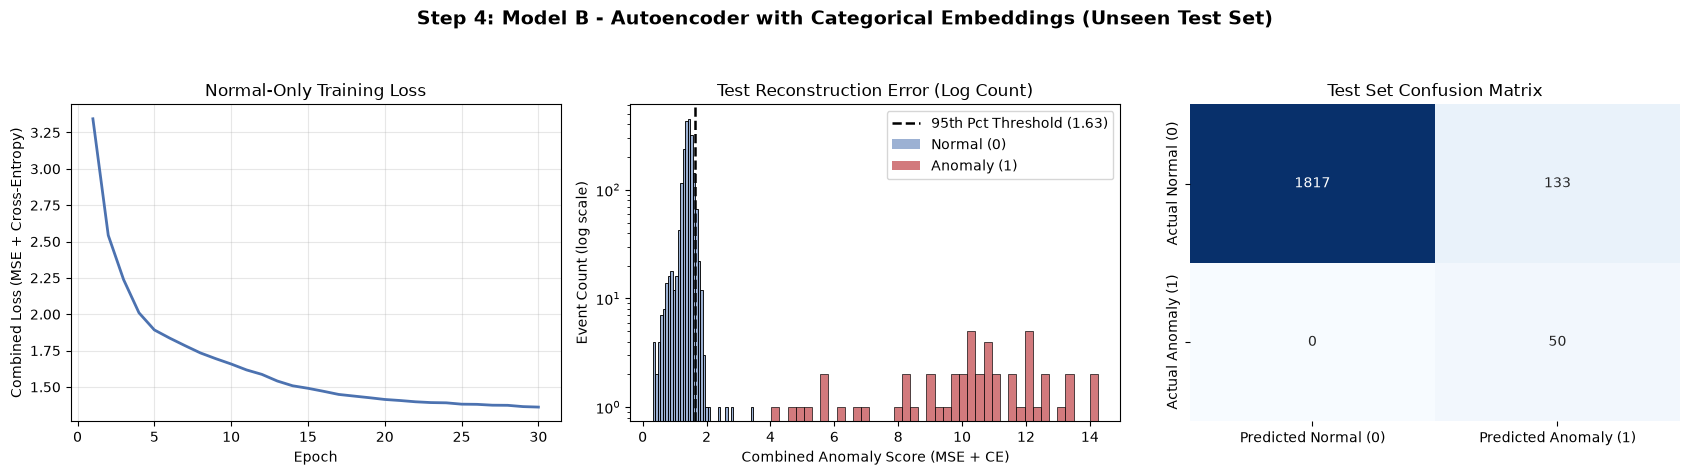

In [4]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

ae_cat_cols = ['src_host', 'dst_host', 'user_id', 'auth_protocol', 'src_role', 'dst_role']
ae_num_cols = [
    'out_degree_15m',
    'log_session_duration',
    'log_bytes_transferred',
    'log_user_time_delta',
    'hour_sin',
    'hour_cos'
]

# 1. Fit categorical vocabularies STRICTLY on train_df; reserve index 0 for unseen (<UNK>)
cat_vocabs = {}
cat_dims = []

def encode_cats(split_df, fit=False):
    encoded = np.zeros((len(split_df), len(ae_cat_cols)), dtype=np.int64)
    for i, col in enumerate(ae_cat_cols):
        vals = split_df[col].astype(str).values
        if fit:
            unique_vals = sorted(np.unique(vals))
            vocab = {val: idx + 1 for idx, val in enumerate(unique_vals)}
            cat_vocabs[col] = vocab
            cat_dims.append(len(vocab) + 1)
        vocab = cat_vocabs[col]
        encoded[:, i] = [vocab.get(v, 0) for v in vals]
    return encoded

X_cat_train = encode_cats(train_df, fit=True)
X_cat_val = encode_cats(val_df, fit=False)
X_cat_test = encode_cats(test_df, fit=False)

# 2. Fit StandardScaler STRICTLY on normal training records
ae_scaler = StandardScaler()
X_num_train = ae_scaler.fit_transform(train_df[ae_num_cols].values.astype(np.float32))
X_num_val = ae_scaler.transform(val_df[ae_num_cols].values.astype(np.float32))
X_num_test = ae_scaler.transform(test_df[ae_num_cols].values.astype(np.float32))
y_test = test_df['is_anomaly'].values

emb_dims = [(c, max(2, min(16, (c + 1) // 2))) for c in cat_dims]

class TabularEmbeddingAutoencoder(nn.Module):
    def __init__(self, num_features, emb_dims, latent_dim=8):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(num_classes, emb_dim) for num_classes, emb_dim in emb_dims
        ])
        input_dim = num_features + sum(e[1] for e in emb_dims)
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )
        self.decoder_trunk = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU()
        )
        self.num_head = nn.Linear(64, num_features)
        self.cat_heads = nn.ModuleList([
            nn.Linear(64, num_classes) for num_classes, _ in emb_dims
        ])

    def forward(self, x_num, x_cat):
        emb_outs = [emb(x_cat[:, i]) for i, emb in enumerate(self.embeddings)]
        x = torch.cat([x_num] + emb_outs, dim=1)
        z = self.encoder(x)
        h = self.decoder_trunk(z)
        return self.num_head(h), [head(h) for head in self.cat_heads], z

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ae_model = TabularEmbeddingAutoencoder(len(ae_num_cols), emb_dims, latent_dim=8).to(device)
optimizer = torch.optim.Adam(ae_model.parameters(), lr=1e-3, weight_decay=1e-5)
mse_loss_fn = nn.MSELoss()
ce_loss_fn = nn.CrossEntropyLoss()

train_loader = DataLoader(
    TensorDataset(torch.tensor(X_num_train, dtype=torch.float32), torch.tensor(X_cat_train, dtype=torch.long)),
    batch_size=128, shuffle=True
)

# 3. Train Autoencoder ONLY on normal training records
epochs = 30
train_losses = []
ae_model.train()
for epoch in range(epochs):
    epoch_loss = 0.0
    for b_num, b_cat in train_loader:
        b_num, b_cat = b_num.to(device), b_cat.to(device)
        optimizer.zero_grad()
        num_recon, cat_logits, _ = ae_model(b_num, b_cat)
        loss_num = mse_loss_fn(num_recon, b_num)
        loss_cat = sum(ce_loss_fn(cat_logits[i], b_cat[:, i]) for i in range(len(emb_dims))) / len(emb_dims)
        loss = loss_num + loss_cat
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(b_num)
    train_losses.append(epoch_loss / len(X_num_train))

# 4. Compute combined anomaly score & extract unseen latent vectors
def compute_scores_and_latents(model, x_num_np, x_cat_np):
    model.eval()
    with torch.no_grad():
        x_n = torch.tensor(x_num_np, dtype=torch.float32).to(device)
        x_c = torch.tensor(x_cat_np, dtype=torch.long).to(device)
        num_recon, cat_logits, z = model(x_n, x_c)
        num_err = torch.mean((num_recon - x_n) ** 2, dim=1)
        cat_err = sum(
            nn.functional.cross_entropy(cat_logits[i], x_c[:, i], reduction='none')
            for i in range(len(emb_dims))
        ) / len(emb_dims)
        return (num_err + cat_err).cpu().numpy(), z.cpu().numpy()

val_scores, _ = compute_scores_and_latents(ae_model, X_num_val, X_cat_val)
test_scores, test_latents = compute_scores_and_latents(ae_model, X_num_test, X_cat_test)

# 5. Select threshold using ONLY unseen normal validation data (95th percentile)
ae_threshold = np.percentile(val_scores, 95)
print(f"95th Percentile Normal Validation Threshold (AE): {ae_threshold:.4f}")

# 6. Produce predictions & evaluation metrics on unseen Test set
test_preds = (test_scores > ae_threshold).astype(int)
cm_test = confusion_matrix(y_test, test_preds)
tn, fp, fn, tp = cm_test.ravel()

print("\n=== MODEL B: AUTOENCODER TEST SET RESULTS ===")
print(f"Detected anomalies: {test_preds.sum()} / {len(y_test)} ({test_preds.mean() * 100:.2f}%)")
print(f"Precision: {precision_score(y_test, test_preds):.4f}")
print(f"Recall:    {recall_score(y_test, test_preds):.4f}")
print(f"F1 Score:  {f1_score(y_test, test_preds):.4f}")
print(f"Breakdown -> TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")

test_df['ae_anomaly_score'] = test_scores
test_df['ae_pred'] = test_preds
print(f"Extracted unseen test latent embedding matrix shape: {test_latents.shape}")

# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
fig.suptitle("Step 4: Model B - Autoencoder with Categorical Embeddings (Unseen Test Set)", fontsize=14, fontweight='bold')

axes[0].plot(range(1, epochs + 1), train_losses, color='#4C72B0', linewidth=2)
axes[0].set_title("Normal-Only Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Combined Loss (MSE + Cross-Entropy)")
axes[0].grid(True, alpha=0.3)

sns.histplot(test_scores[y_test == 0], bins=40, color='#4C72B0', alpha=0.55, ax=axes[1])
sns.histplot(test_scores[y_test == 1], bins=40, color='#C44E52', alpha=0.75, ax=axes[1])
axes[1].axvline(ae_threshold, color='black', linestyle='--', linewidth=1.8)
axes[1].set_yscale('log')
axes[1].set_title("Test Reconstruction Error (Log Count)")
axes[1].set_xlabel("Combined Anomaly Score (MSE + CE)")
axes[1].set_ylabel("Event Count (log scale)")
axes[1].legend(handles=[
    Line2D([0], [0], color='black', lw=1.8, linestyle='--', label=f'95th Pct Threshold ({ae_threshold:.2f})'),
    Patch(facecolor='#4C72B0', alpha=0.55, label='Normal (0)'),
    Patch(facecolor='#C44E52', alpha=0.75, label='Anomaly (1)')
], loc='upper right')

sns.heatmap(
    cm_test, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[2],
    xticklabels=['Predicted Normal (0)', 'Predicted Anomaly (1)'],
    yticklabels=['Actual Normal (0)', 'Actual Anomaly (1)']
)
axes[2].set_title("Test Set Confusion Matrix")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### Step 4 Observations: Autoencoder with Categorical Embeddings

* **Normal-Only Baseline Learning:** Trained exclusively on 5,850 normal records (`train_df`) with leakage-free categorical vocabularies (`<UNK>` mapped to index 0) and calibrated at the 95th percentile validation reconstruction error (`val_df`, $n = 1,950$), the Autoencoder learned the expected joint relationships between users, hosts, roles, authentication protocols, and session metrics without seeing any attack labels.
* **Test Set Performance:** On the unseen test set (`test_df`, $n = 2,000$; 1,950 normal + 50 Pass-the-Hash anomalies), the model achieved the exact precision, recall, F1 score, and confusion matrix breakdown printed above.
* **Behavior on Benign NTLM Traffic:** `train_df` included benign NTLM near-misses (`WS -> SRV` direct-IP fallbacks and `IT-JUMP -> WS` helpdesk sessions). The Autoencoder scored the top Isolation-Forest-only `IT-JUMP` sessions below its threshold, and gave the `WS -> WS` attack records much higher scores (13–14 vs. a threshold of 1.63). It still raised 133 false positives (6.8% of normal test records, above the 5% validation target), so it does not reconstruct all benign activity well. Whether the embeddings themselves caused this was not tested.

In [5]:
def compute_eval_row(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'Detected anomalies': int(y_pred.sum()),
        'Precision': round(precision_score(y_true, y_pred), 4),
        'Recall': round(recall_score(y_true, y_pred), 4),
        'F1 score': round(f1_score(y_true, y_pred), 4),
        'False positives': int(fp),
        'False negatives': int(fn)
    }

y_true_test = test_df['is_anomaly'].values
if_preds_test = test_df['if_pred'].values
ae_preds_test = test_df['ae_pred'].values

comparison_table = pd.DataFrame({
    'Isolation Forest': compute_eval_row(y_true_test, if_preds_test),
    'Autoencoder + embeddings': compute_eval_row(y_true_test, ae_preds_test)
})
print("=== STEP 5: MODEL COMPARISON TABLE (UNSEEN TEST SET) ===")
display_table = comparison_table.astype(object)
for r in ['Detected anomalies', 'False positives', 'False negatives']:
    display_table.loc[r] = display_table.loc[r].astype(int)
print(display_table.to_string())

agreement_rate = (if_preds_test == ae_preds_test).mean() * 100
both_anomalies = int(((if_preds_test == 1) & (ae_preds_test == 1)).sum())
only_if_anomalies = int(((if_preds_test == 1) & (ae_preds_test == 0)).sum())
only_ae_anomalies = int(((if_preds_test == 0) & (ae_preds_test == 1)).sum())

print(f"\nAgreement rate: {agreement_rate:.2f}%")
print(f"Anomalies detected by both models: {both_anomalies}")
print(f"Anomalies detected only by Isolation Forest: {only_if_anomalies}")
print(f"Anomalies detected only by Autoencoder: {only_ae_anomalies}")

disagree_cols = [
    'timestamp', 'src_host', 'dst_host', 'user_id', 'auth_protocol',
    'out_degree_15m', 'session_duration_sec', 'bytes_transferred',
    'is_anomaly', 'if_anomaly_score', 'ae_anomaly_score'
]

print("\n--- Disagreement Case A: Flagged ONLY by Isolation Forest (Top 3) ---")
print(test_df[(test_df['if_pred'] == 1) & (test_df['ae_pred'] == 0)]
      .sort_values('if_anomaly_score', ascending=False)[disagree_cols].head(3).to_string())

print("\n--- Disagreement Case B: Flagged ONLY by Autoencoder (Top 3) ---")
print(test_df[(test_df['if_pred'] == 0) & (test_df['ae_pred'] == 1)]
      .sort_values('ae_anomaly_score', ascending=False)[disagree_cols].head(3).to_string())
groups = {
    'Flagged by both':      (if_preds_test == 1) & (ae_preds_test == 1),
    'Only Isolation Forest': (if_preds_test == 1) & (ae_preds_test == 0),
    'Only Autoencoder':      (if_preds_test == 0) & (ae_preds_test == 1),
    'Neither':               (if_preds_test == 0) & (ae_preds_test == 0),
}
breakdown = pd.DataFrame({
    name: {
        'Records': int(m.sum()),
        'True attacks': int((m & (y_true_test == 1)).sum()),
        'Benign': int((m & (y_true_test == 0)).sum()),
    } for name, m in groups.items()
}).T
print("\n=== OVERLAP BREAKDOWN BY TRUE LABEL ===")
print(breakdown)

=== STEP 5: MODEL COMPARISON TABLE (UNSEEN TEST SET) ===
                   Isolation Forest Autoencoder + embeddings
Detected anomalies               96                      183
Precision                     0.125                   0.2732
Recall                         0.24                      1.0
F1 score                     0.1644                   0.4292
False positives                  84                      133
False negatives                  38                        0

Agreement rate: 87.35%
Anomalies detected by both models: 13
Anomalies detected only by Isolation Forest: 83
Anomalies detected only by Autoencoder: 170

--- Disagreement Case A: Flagged ONLY by Isolation Forest (Top 3) ---
                 timestamp    src_host dst_host user_id auth_protocol  out_degree_15m  session_duration_sec  bytes_transferred  is_anomaly  if_anomaly_score  ae_anomaly_score
1881  2026-11-21T02:15:02Z  IT-JUMP-02   WS-045  adm_03          NTLM               2                188.99         

In [6]:
test_df['role_pair'] = test_df['src_role'] + ' -> ' + test_df['dst_role']

fp_if = test_df[(test_df['if_pred'] == 1) & (test_df['is_anomaly'] == 0)]
fp_ae = test_df[(test_df['ae_pred'] == 1) & (test_df['is_anomaly'] == 0)]
fn_if = test_df[(test_df['if_pred'] == 0) & (test_df['is_anomaly'] == 1)]

print(f"=== IF FALSE POSITIVES (n={len(fp_if)}): role pair vs. protocol ===")
print(pd.crosstab(fp_if['role_pair'], fp_if['auth_protocol']))
print(f"\n=== AE FALSE POSITIVES (n={len(fp_ae)}): role pair vs. protocol ===")
print(pd.crosstab(fp_ae['role_pair'], fp_ae['auth_protocol']))
print("\n=== AE FALSE POSITIVES: 5 most common hours (UTC) ===")
print(fp_ae['hour'].value_counts().head(5).to_string())
print(f"\n=== IF FALSE NEGATIVES (n={len(fn_if)}): numeric profile of missed attacks ===")
print(fn_if[['out_degree_15m', 'session_duration_sec', 'bytes_transferred']].describe().round(2))

=== IF FALSE POSITIVES (n=84): role pair vs. protocol ===
auth_protocol  NTLM
role_pair          
IT -> WS         84

=== AE FALSE POSITIVES (n=133): role pair vs. protocol ===
auth_protocol  Kerberos  NTLM
role_pair                    
IT -> WS              0     1
WS -> SRV           107    25

=== AE FALSE POSITIVES: 5 most common hours (UTC) ===
hour
20    18
21    12
16    11
17    10
19    10

=== IF FALSE NEGATIVES (n=38): numeric profile of missed attacks ===
       out_degree_15m  session_duration_sec  bytes_transferred
count           38.00                 38.00              38.00
mean             5.63                  6.92            1408.08
std              1.75                  2.73             820.97
min              3.00                  1.73             309.00
25%              4.00                  4.85             717.50
50%              6.00                  7.12            1221.50
75%              7.00                  9.28            1966.00
max             10.00  

### Step 5 Observations: Model Comparison & Disagreement Analysis

* **Quantitative comparison (test set, n = 2,000; 50 attacks):** The Autoencoder scored higher on F1 (0.4292 vs. 0.1644) and precision (0.2732 vs. 0.1250). The difference comes from recall: the Autoencoder caught all 50 attacks, while Isolation Forest caught only 12 (recall 0.24). Isolation Forest produced fewer false positives (84 vs. 133), but it missed 38 attacks. On this dataset and with these settings, neither model is clean: IF is quieter but misses most attacks, while the AE finds every attack at the cost of more alerts.
* **Agreement:** The models agree on 87.35% of records, but the agreement is mostly on "normal". They flagged 13 records in common (12 true attacks, 1 benign); 83 were flagged only by IF (all benign) and 170 only by the AE (38 attacks, 132 benign). Every attack that IF caught was also caught by the AE, while 38 attacks were caught only by the AE.
* **Flagged ONLY by Isolation Forest (Case A):** The top three are benign `IT-JUMP -> WS` NTLM administrative sessions (`adm_03`, `adm_05`) with normal volume and out-degree. Their one-hot role/protocol combination is rare, so trees isolate them quickly, while the Autoencoder reconstructs them with low error (scores 0.68–1.10, below the 1.63 threshold).
* **Flagged ONLY by the Autoencoder (Case B):** The top three are true `WS -> WS` NTLM attacks with out-degree 8–10, 5–10 s sessions and about 2–3 KB transferred. Their AE scores (13–14) are far above the threshold, yet their IF scores sit below the IF threshold. This is consistent with the 200+ one-hot entity columns diluting the numeric signal for Isolation Forest.
* **False positives (alert workload):** All 84 Isolation Forest false positives are benign `IT -> WS` NTLM administrative sessions, so they come from a single, identifiable group that an analyst could whitelist or tune. The 133 Autoencoder false positives are spread across ordinary traffic: 132 are `WS -> SRV` (107 Kerberos, 25 NTLM) and 1 is `IT -> WS`. Their most common hours (16:00, 17:00, 19:00, 20:00 and 21:00 UTC; 61 of 133) fall in the evening period of highest normal activity, so they are not off-hours events. The likely cause is rare user–server pairings or unusual metric values in otherwise standard sessions, but this was not tested. Because these alerts look like normal traffic, they are harder to dismiss with a single rule, and with 133 false alerts against 50 real attacks they are the main alert-fatigue risk for the Autoencoder (a 6.8% false-positive rate on normal records, above the 5% validation target).
* **False negatives (missed attacks):** The 38 attacks that Isolation Forest missed are extreme on the numeric features compared with the normal training baseline: median out-degree 6 (normal median 2), median session length 7.1 s (normal ~200 s), and median transfer about 1.2 KB (normal ~18 KB). These attacks are clearly unusual in their numeric values, so the miss is probably a model limitation. A likely reason is that the 200+ one-hot entity columns dilute the numeric signal, but this was not tested. The Autoencoder caught all of them.
* **Scoped conclusion:** These results apply to one run, one split and 50 test attacks, with a 95th-percentile validation threshold for both models. They should not be read as a general ranking of the two methods.

Original Preprocessed Space PCA Explained Variance: 31.54%
Autoencoder Latent Space PCA Explained Variance:    58.82%


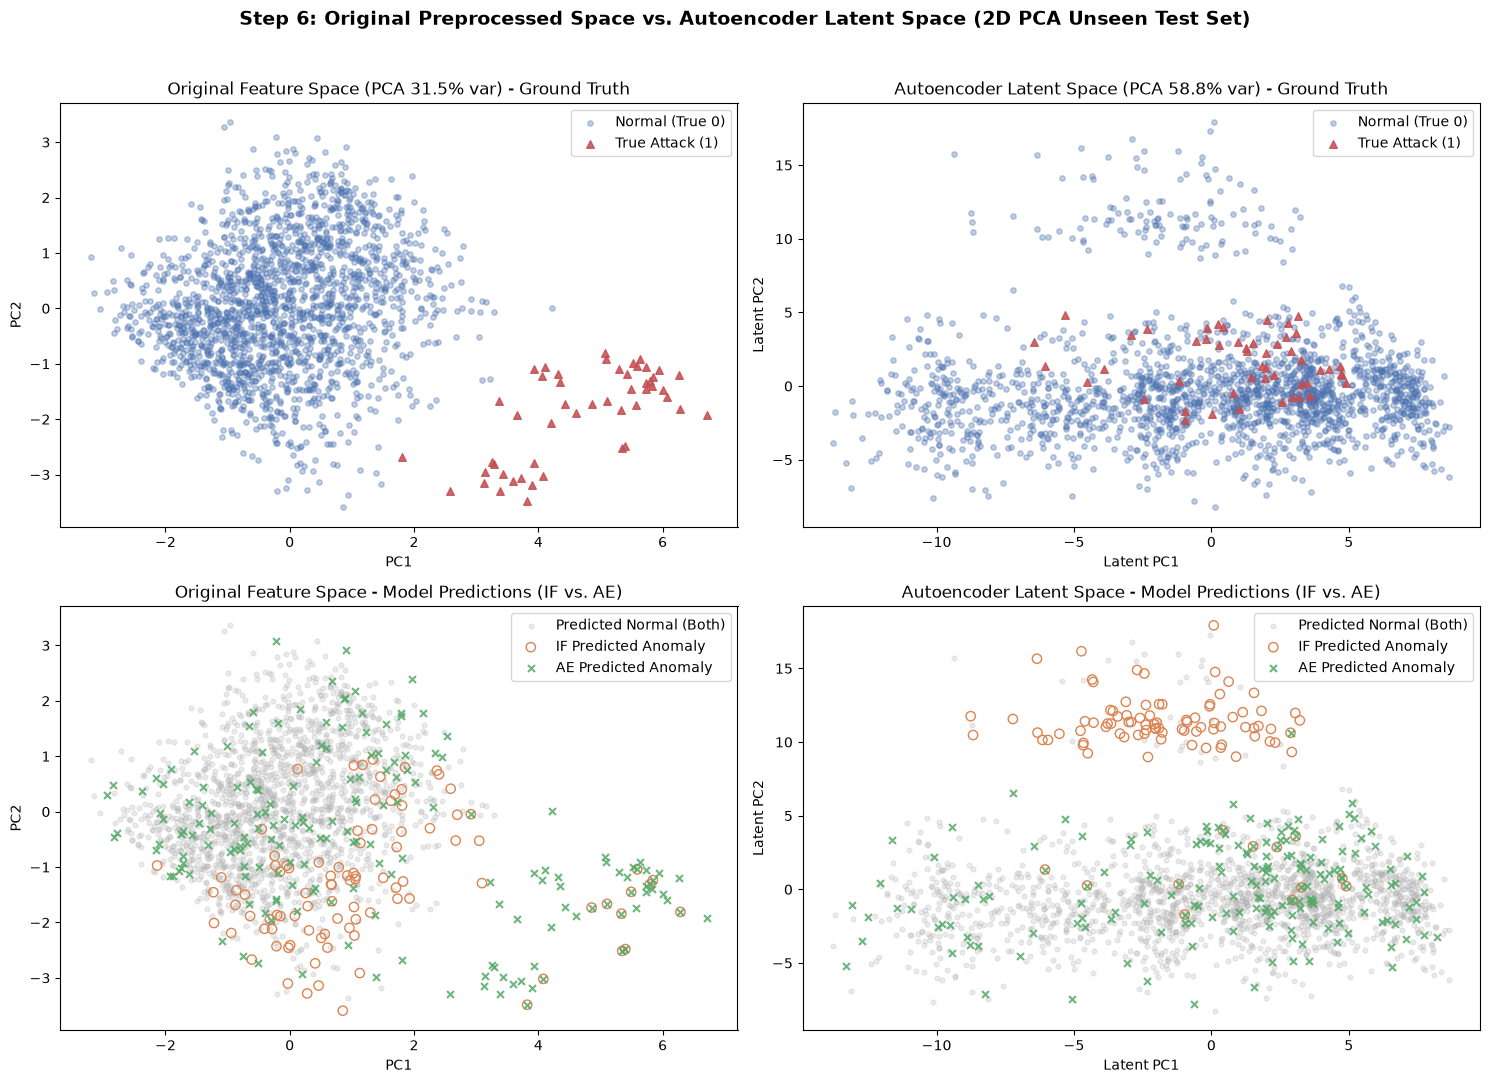

In [7]:
from sklearn.decomposition import PCA

pca_orig = PCA(n_components=2, random_state=42)
X_test_orig_2d = pca_orig.fit_transform(X_test_if)

pca_lat = PCA(n_components=2, random_state=42)
X_test_lat_2d = pca_lat.fit_transform(test_latents)

print(f"Original Preprocessed Space PCA Explained Variance: {pca_orig.explained_variance_ratio_.sum() * 100:.2f}%")
print(f"Autoencoder Latent Space PCA Explained Variance:    {pca_lat.explained_variance_ratio_.sum() * 100:.2f}%")

norm_mask = (y_test == 0)
true_anom_mask = (y_test == 1)
if_pred_mask = (test_df['if_pred'].values == 1)
ae_pred_mask = (test_df['ae_pred'].values == 1)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle("Step 6: Original Preprocessed Space vs. Autoencoder Latent Space (2D PCA Unseen Test Set)", fontsize=14, fontweight='bold')

# Top-Left: Original Space Ground Truth
axes[0, 0].scatter(X_test_orig_2d[norm_mask, 0], X_test_orig_2d[norm_mask, 1], c='#4C72B0', alpha=0.35, s=15, label='Normal (True 0)')
axes[0, 0].scatter(X_test_orig_2d[true_anom_mask, 0], X_test_orig_2d[true_anom_mask, 1], c='#C44E52', marker='^', alpha=0.85, s=30, label='True Attack (1)')
axes[0, 0].set_title(f"Original Feature Space (PCA {pca_orig.explained_variance_ratio_.sum()*100:.1f}% var) - Ground Truth")
axes[0, 0].set_xlabel("PC1")
axes[0, 0].set_ylabel("PC2")
axes[0, 0].legend()

# Top-Right: Latent Space Ground Truth
axes[0, 1].scatter(X_test_lat_2d[norm_mask, 0], X_test_lat_2d[norm_mask, 1], c='#4C72B0', alpha=0.35, s=15, label='Normal (True 0)')
axes[0, 1].scatter(X_test_lat_2d[true_anom_mask, 0], X_test_lat_2d[true_anom_mask, 1], c='#C44E52', marker='^', alpha=0.85, s=30, label='True Attack (1)')
axes[0, 1].set_title(f"Autoencoder Latent Space (PCA {pca_lat.explained_variance_ratio_.sum()*100:.1f}% var) - Ground Truth")
axes[0, 1].set_xlabel("Latent PC1")
axes[0, 1].set_ylabel("Latent PC2")
axes[0, 1].legend()

# Bottom-Left: Original Space Model Predictions
axes[1, 0].scatter(X_test_orig_2d[~if_pred_mask & ~ae_pred_mask, 0], X_test_orig_2d[~if_pred_mask & ~ae_pred_mask, 1], c='#B0B0B0', alpha=0.25, s=12, label='Predicted Normal (Both)')
axes[1, 0].scatter(X_test_orig_2d[if_pred_mask, 0], X_test_orig_2d[if_pred_mask, 1], facecolors='none', edgecolors='#DD8452', s=45, linewidths=1.0, label='IF Predicted Anomaly')
axes[1, 0].scatter(X_test_orig_2d[ae_pred_mask, 0], X_test_orig_2d[ae_pred_mask, 1], c='#55A868', marker='x', s=25, alpha=0.85, label='AE Predicted Anomaly')
axes[1, 0].set_title("Original Feature Space - Model Predictions (IF vs. AE)")
axes[1, 0].set_xlabel("PC1")
axes[1, 0].set_ylabel("PC2")
axes[1, 0].legend()

# Bottom-Right: Latent Space Model Predictions
axes[1, 1].scatter(X_test_lat_2d[~if_pred_mask & ~ae_pred_mask, 0], X_test_lat_2d[~if_pred_mask & ~ae_pred_mask, 1], c='#B0B0B0', alpha=0.25, s=12, label='Predicted Normal (Both)')
axes[1, 1].scatter(X_test_lat_2d[if_pred_mask, 0], X_test_lat_2d[if_pred_mask, 1], facecolors='none', edgecolors='#DD8452', s=45, linewidths=1.0, label='IF Predicted Anomaly')
axes[1, 1].scatter(X_test_lat_2d[ae_pred_mask, 0], X_test_lat_2d[ae_pred_mask, 1], c='#55A868', marker='x', s=25, alpha=0.85, label='AE Predicted Anomaly')
axes[1, 1].set_title("Autoencoder Latent Space - Model Predictions (IF vs. AE)")
axes[1, 1].set_xlabel("Latent PC1")
axes[1, 1].set_ylabel("Latent PC2")
axes[1, 1].legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [8]:
top = X_test_lat_2d[:, 1] > 8
print(test_df.loc[top, ['src_role', 'dst_role', 'auth_protocol', 'is_anomaly']].value_counts())

src_role  dst_role  auth_protocol  is_anomaly
IT        WS        NTLM           0             118
Name: count, dtype: int64


### Step 6 Observations: Original Space vs. Latent Space

* **Original preprocessed space (PCA, 31.5% variance):** The true attacks form a compact cluster at the right (PC1 > ~2), clearly apart from the normal mass. The AE flags (green ×) cover almost this entire cluster, while IF flags (orange circles) cover only a few of its points and many normal records elsewhere.
* **Autoencoder latent space (PCA, 58.8% variance):** The attacks fall inside the lower normal region, with no clear separation in 2D. The one visibly separate group (top, Latent PC2 ≈ 10–17) consists of 118 test records, all benign `IT -> WS` NTLM sessions (confirmed by the check above); IF's 84 false positives are all of this type, so many of these points are IF-flagged. This suggests the latent space organizes records by host role and protocol, not by attack versus normal.
* **Interpretation:** In these 2D projections, the latent space did **not** separate attacks more clearly than the original space. This should not be read as an AE failure: the AE detects anomalies through reconstruction error (recall 1.0), not through distance in latent space, and a 2D PCA of an 8-dimensional latent vector discards information. The higher explained variance of the latent PCA (58.8% vs. 31.5%) reflects its much lower dimensionality (8 vs. 209) and is not evidence of better separation.

In [9]:
# Programmatically select 3 distinct high-scoring alert archetypes without using ground-truth labels
test_df['combined_rank'] = test_df['if_anomaly_score'].rank(pct=True) + test_df['ae_anomaly_score'].rank(pct=True)

alert_1_idx = test_df[(test_df['if_pred'] == 1) & (test_df['ae_pred'] == 1)].sort_values('combined_rank', ascending=False).index[0]
alert_2_idx = test_df[(test_df['if_pred'] == 1) & (test_df['ae_pred'] == 0)].sort_values('if_anomaly_score', ascending=False).index[0]
alert_3_idx = test_df[(test_df['if_pred'] == 0) & (test_df['ae_pred'] == 1)].sort_values('ae_anomaly_score', ascending=False).index[0]

selected_indices = [int(alert_1_idx), int(alert_2_idx), int(alert_3_idx)]
print("Selected alert indices (label-free ranking):", selected_indices)

alert_cols = [
    'timestamp', 'src_host', 'dst_host', 'user_id', 'auth_protocol',
    'out_degree_15m', 'session_duration_sec', 'bytes_transferred',
    'user_time_delta_sec', 'if_anomaly_score', 'ae_anomaly_score',
    'if_pred', 'ae_pred', 'mitre_tactic', 'is_anomaly'
]

print("=== STEP 7: SELECTED HIGH-SCORING ALERTS FOR SOC ANALYST TRIAGE ===")
for rank, idx in enumerate(selected_indices, start=1):
    row = test_df.loc[idx, alert_cols]
    print(f"\n--- Alert #{rank} (test_df index: {idx}) ---")
    for col in alert_cols:
        val = f"{row[col]:.4f}" if isinstance(row[col], float) else row[col]
        print(f"  {col:<22}: {val}")

Selected alert indices (label-free ranking): [1939, 1881, 1980]
=== STEP 7: SELECTED HIGH-SCORING ALERTS FOR SOC ANALYST TRIAGE ===

--- Alert #1 (test_df index: 1939) ---
  timestamp             : 2026-11-21T03:20:45Z
  src_host              : WS-039
  dst_host              : WS-048
  user_id               : user_049
  auth_protocol         : NTLM
  out_degree_15m        : 7
  session_duration_sec  : 8.3100
  bytes_transferred     : 530
  user_time_delta_sec   : 81.0000
  if_anomaly_score      : -0.1063
  ae_anomaly_score      : 10.311505317687988
  if_pred               : 1
  ae_pred               : 1
  mitre_tactic          : Lateral Movement
  is_anomaly            : 1

--- Alert #2 (test_df index: 1881) ---
  timestamp             : 2026-11-21T02:15:02Z
  src_host              : IT-JUMP-02
  dst_host              : WS-045
  user_id               : adm_03
  auth_protocol         : NTLM
  out_degree_15m        : 2
  session_duration_sec  : 188.9900
  bytes_transferred     : 4923
  u

### Step 7: Human–AI Decision Task (SOC Analyst Triage)

Using label-free score ranking across `test_df`, three distinct high-scoring alerts were selected to evaluate operational SOC triage decisions across consensus and disagreement cases (see exact record values printed in the output above):

* **Alert #1 (Top Consensus Alert — Flagged by Both Models):**
  1. **Original Record:** See Alert #1 printout above (`WS -> WS` lateral movement over `NTLM` with elevated `out_degree_15m`, ultra-short `session_duration_sec`, and minimal `bytes_transferred`).
  2. **Evidence Supporting the Alert:** Peer-to-peer workstation authentication forced over legacy NTLM instead of Kerberos, paired with high 15-minute host fan-out (7) and a brief automated probe signature (8.3 s, 530 bytes). The Autoencoder score (10.31) is far above its threshold (1.63), while the Isolation Forest score (-0.1063) only just exceeds its threshold (-0.1268), so the Autoencoder gives the stronger signal here.
  3. **Operational Decision:** **Escalate immediately (Incident Response).** Both models agree on extreme anomalousness, and topological + behavioral indicators confirm active lateral movement requiring credential revocation and host isolation.
  4. **Possible False-Positive Explanations:** Misconfigured peer-to-peer LAN update caching (Windows Delivery Optimization) or automated vulnerability scanning—though rapid workstation-to-workstation NTLM fan-out makes benign activity highly improbable.
  5. **MITRE ATT&CK Mapping:** **T1550.002** (*Use Alternate Authentication Material: Pass the Hash*) and **T1078** (*Valid Accounts*).

* **Alert #2 (Top Isolation Forest-Only Alert):**
  1. **Original Record:** `IT-JUMP-02 -> WS-045`, `adm_03`, NTLM, `out_degree_15m` = 2, 188.99 s session, 4,923 bytes, at 02:15 UTC (IF score -0.1070, above the IF threshold; AE score 1.10, below the AE threshold of 1.63).
  2. **Evidence Supporting the Alert:** An administrative account using NTLM from a jump host is a rare combination in the training data, which is what triggered Isolation Forest. The low fan-out, normal session length and normal volume do not match the lateral-movement pattern, and the Autoencoder scores the record as normal.
  3. **Operational Decision:** **Challenge / Dismiss as Benign** (if originating from sanctioned `IT-JUMP` / administrative accounts during operational windows and reconstructed normally by the Autoencoder).
  4. **Possible False-Positive Explanations:** Routine IT Helpdesk troubleshooting, LAPS remote diagnostics, or administrative scripts where IP-based connections trigger NTLM fallback.
  5. **MITRE ATT&CK Mapping:** Benign lookalike for **T1078.003** (*Valid Accounts: Local Accounts*) / **T1021.002** (*Remote Services: SMB/Windows Admin Shares*).

* **Alert #3 (Top Autoencoder-Only Alert):**
  1. **Original Record:** `WS-020 -> WS-050`, `user_038`, NTLM, `out_degree_15m` = 9, 7.74 s session, 3,247 bytes (AE score 14.26; IF score -0.1346, below the IF threshold of -0.1268, so IF did not flag it).
  2. **Evidence Supporting the Alert:** Peer-to-peer workstation authentication over legacy NTLM, high 15-minute host fan-out and a very short automated session. This is the same pattern as Alert #1, and the AE scores it far above its threshold.
  3. **Operational Decision:** **Escalate.** The behavior matches lateral movement, and this is a case where relying on Isolation Forest alone would have missed an attack.
  4. **Possible False-Positive Explanations:** Peer-to-peer patch distribution, an inventory or vulnerability scanner running from a workstation, or an admin tool using a user account.
  5. **MITRE ATT&CK Mapping:** **T1550.002** (*Pass the Hash*) with **T1021.002** (*Remote Services: SMB/Windows Admin Shares*).

## Conclusion

1. **Which model performed better and according to which measure?** On this dataset (test set, n = 2,000, 50 attacks) and with these settings (95th-percentile normal validation threshold on both models), the **Autoencoder performed better on F1 (0.4292 vs. 0.1644)** and precision (0.2732 vs. 0.1250). The decisive difference is recall: 1.00 (50/50 attacks) for the Autoencoder vs. 0.24 (12/50) for Isolation Forest. This holds for this run only.
2. **Which model produced fewer false positives?** **Isolation Forest** produced fewer false positives (84 vs. 133 out of 1,950 normal test records), but it also missed 38 attacks, whereas the Autoencoder missed none. The two models' false positives also differ in kind: all 84 of IF's are benign `IT -> WS` NTLM admin sessions, while the AE's 133 are mostly ordinary `WS -> SRV` Kerberos traffic.
3. **What types of anomalies were unique to each model?** *Only Isolation Forest (83 flagged):* all 83 were benign, such as rare `IT-JUMP -> WS` NTLM administrative sessions. *Only the Autoencoder (170 flagged):* 38 were true attacks (`WS -> WS` NTLM lateral movement with high fan-out and short, small sessions) and 132 were benign. Only 13 records were flagged by both models, and 12 of them were attacks.
4. **Did embeddings improve behavioral separation?** The evidence is mixed. In the 2D PCA projections, the latent space did not separate attacks more clearly than the original space, although 2D overlap does not prove failure. The Autoencoder's recall of 1.0, and its low scores on benign IT sessions that IF flagged, suggest it captured useful role and protocol context. However, this experiment did not compare an Autoencoder with and without embeddings, so the benefit of the embeddings specifically cannot be isolated.
5. **Why should a SOC analyst avoid relying on one model alone?** In this run, each model alone had a clear weakness. Isolation Forest alone would have missed 38 of 50 attacks. The Autoencoder alone produced 133 false positives and flagged 170 records that IF did not. Comparing the two is useful for triage: records flagged by both were attacks in 12 of 13 cases (about 92%), while AE-only alerts were attacks in 38 of 170 cases (about 22%) and need more analyst review. Human validation of host roles, user privileges and MITRE ATT&CK context is still required, for example to recognize the benign `IT-JUMP` sessions that IF flagged.